In [3]:
# Importing necessary libraries
import numpy as np            # For numerical operations
import pandas as pd           # For data manipulation and analysis
import matplotlib.pyplot as plt # For data visualization
import warnings
warnings.filterwarnings('ignore')

# Importing wordcloud for text visualization
from wordcloud import WordCloud

# Importing NLTK for natural language processing
import nltk
from nltk.corpus import stopwords  # For stopwords

# Downloading NLTK data
nltk.download('stopwords')   # Downloading stopwords data
nltk.download('punkt')       # Downloading tokenizer data


[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\vishesh\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\vishesh\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\vishesh\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


True

In [4]:
df = pd.read_csv("D:/CODES/MLOPS/mlops-complete-pipeline/experiments/spam.csv")
df.head()

,v1,v2,Unnamed: 2,Unnamed: 3,Unnamed: 4
0,ham,"Go until jurong point, crazy.. Available only ...",NaN,NaN,NaN
1,ham,Ok lar... Joking wif u oni...,NaN,NaN,NaN
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,NaN,NaN,NaN
3,ham,U dun say so early hor... U c already then say...,NaN,NaN,NaN
4,ham,"Nah I don't think he goes to usf, he lives aro...",NaN,NaN,NaN


In [5]:
df_copy = df.copy()

In [6]:
df_copy.head()

,v1,v2,Unnamed: 2,Unnamed: 3,Unnamed: 4
0,ham,"Go until jurong point, crazy.. Available only ...",NaN,NaN,NaN
1,ham,Ok lar... Joking wif u oni...,NaN,NaN,NaN
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,NaN,NaN,NaN
3,ham,U dun say so early hor... U c already then say...,NaN,NaN,NaN
4,ham,"Nah I don't think he goes to usf, he lives aro...",NaN,NaN,NaN


In [7]:
df_copy.shape

(5572, 5)

In [8]:
df_copy.info()

<class 'pandas.DataFrame'>
RangeIndex: 5572 entries, 0 to 5571
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   v1          5572 non-null   str  
 1   v2          5572 non-null   str  
 2   Unnamed: 2  50 non-null     str  
 3   Unnamed: 3  12 non-null     str  
 4   Unnamed: 4  6 non-null      str  
dtypes: str(5)
memory usage: 217.8 KB


preprocessing

In [9]:
df_copy.drop(columns=['Unnamed: 2','Unnamed: 3','Unnamed: 4'],inplace=True)
df_copy.head()

,v1,v2
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


In [10]:
df_copy.rename(
    columns= {
        'v1' : 'target',
        'v2' : 'text'
    },
    inplace=True
)
df_copy.info()

<class 'pandas.DataFrame'>
RangeIndex: 5572 entries, 0 to 5571
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   target  5572 non-null   str  
 1   text    5572 non-null   str  
dtypes: str(2)
memory usage: 87.2 KB


In [11]:
df_copy.sample(10)

,target,text
3131,ham,I've been barred from all B and Q stores for l...
4244,ham,Is toshiba portege m100 gd?
827,ham,Hey. You got any mail?
2505,ham,Congrats kano..whr s the treat maga?
2616,ham,I went to ur hon lab but no one is there.
2835,ham,Nice.nice.how is it working?
4530,ham,I wish things were different. I wonder when i ...
4003,ham,Well there's a pattern emerging of my friends ...
1242,ham,Nobody can decide where to eat and dad wants C...
3499,spam,Dorothy@kiefer.com (Bank of Granite issues Str...


In [12]:
df_copy.shape

(5572, 2)

In [13]:
df_copy['target'].unique()

<StringArray>
['ham', 'spam']
Length: 2, dtype: str

In [14]:
df_copy.isnull().sum()

target    0
text      0
dtype: int64

In [15]:
df_copy.duplicated().sum()

np.int64(403)

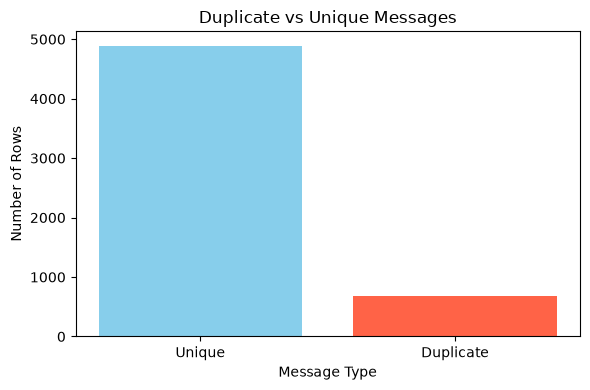

In [16]:
duplicate_counts = df_copy["text"].duplicated(keep=False).value_counts()
labels = {False: "Unique", True: "Duplicate"}

plt.figure(figsize=(6, 4))
plt.bar(
    [labels[x] for x in duplicate_counts.index],
    duplicate_counts.values,
    color=["skyblue", "tomato"],
)
plt.title("Duplicate vs Unique Messages")
plt.xlabel("Message Type")
plt.ylabel("Number of Rows")
plt.tight_layout()
plt.show()

In [17]:
df_copy = df_copy.drop_duplicates(keep='first')
print("after removing the duplicate values : ",df_copy.shape)

after removing the duplicate values :  (5169, 2)


feature engineering

In [18]:
from sklearn.preprocessing import LabelEncoder

label_encoder = LabelEncoder()
df_copy['target'] = label_encoder.fit_transform(df_copy['target'])

In [19]:
df_copy.head()

,target,text
0,0,"Go until jurong point, crazy.. Available only ..."
1,0,Ok lar... Joking wif u oni...
2,1,Free entry in 2 a wkly comp to win FA Cup fina...
3,0,U dun say so early hor... U c already then say...
4,0,"Nah I don't think he goes to usf, he lives aro..."


In [20]:
# import the porter stemmer for text stemming

from nltk.stem.porter import PorterStemmer
import string

ps = PorterStemmer()

In [23]:
def transform_text(text):
    #1. transform capital text to lower case
    text = text.lower()
    
    #2. tokenization using tltk
    text = nltk.word_tokenize(text)
    
    # removing special chracter (alphanumeric)
    y = []
    for i in text:
        if i.isalnum():
            y.append(i)
            
    # removing stop words and punctuation
    text = y[:]
    y.clear()
    
    # loop through the tokens and remove stopwords and punctuation
    for i in text:
        if i not in stopwords.words('english') and i not in string.punctuation:
            y.append(i)
            
    # stemming using porter stemmer
    text = y[:]
    y.clear()
    for i in text:
        y.append(ps.stem(i))
        
    # join the processed token back into a single string
    return " ".join(y)

In [24]:
transform_text('Go until jurong point, crazy.. Available only in bugis n great world la e buffet.. Cine there got amore wat...')

'go jurong point crazi avail bugi n great world la e buffet cine got amor wat'

In [25]:
df_copy['transformed_text'] = df_copy['text'].apply(transform_text)
df_copy.head()

,target,text,transformed_text
0,0,"Go until jurong point, crazy.. Available only ...",go jurong point crazi avail bugi n great world...
1,0,Ok lar... Joking wif u oni...,ok lar joke wif u oni
2,1,Free entry in 2 a wkly comp to win FA Cup fina...,free entri 2 wkli comp win fa cup final tkt 21...
3,0,U dun say so early hor... U c already then say...,u dun say earli hor u c alreadi say
4,0,"Nah I don't think he goes to usf, he lives aro...",nah think goe usf live around though


In [26]:
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer

tfid = TfidfVectorizer(max_features=500)

X = tfid.fit_transform(df_copy['transformed_text']).toarray()
y = df_copy['target'].values

In [27]:
from sklearn.model_selection import train_test_split
x_train, x_test, y_train, y_test = train_test_split(X,y, test_size=0.20,random_state=2)

In [37]:
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier, BaggingClassifier,ExtraTreesClassifier,GradientBoostingClassifier
from xgboost import XGBClassifier
from catboost import CatBoostClassifier

In [38]:
 
# Create all model instances from the imported classifiers
models = {}

# Standard classifiers
models["SVC"] = SVC(kernel='sigmoid',gamma=1.0)
models["LogisticRegression"] = LogisticRegression(solver='liblinear', penalty='l1')
models["MultinomialNB"] = MultinomialNB()
models["DecisionTreeClassifier"] = DecisionTreeClassifier(max_depth=5, random_state=2)
models["KNeighborsClassifier"] = KNeighborsClassifier(n_neighbors=200)

# Ensemble models
models["RandomForestClassifier"] = RandomForestClassifier(n_estimators=50,random_state=2)
models["AdaBoostClassifier"] = AdaBoostClassifier(n_estimators=50,random_state=2)
models["BaggingClassifier"] = BaggingClassifier(n_estimators=50,random_state=2)
models["ExtraTreesClassifier"] = ExtraTreesClassifier(n_estimators=50,random_state=2)
models["GradientBoostingClassifier"] = GradientBoostingClassifier(n_estimators=50,random_state=2)
models["XGBClassifier"] = XGBClassifier(random_state=2, eval_metric="logloss")
models["CatBoostClassifier"] = CatBoostClassifier(
    iterations=100,
    learning_rate=0.1,
    depth=6,
    random_seed=2,
    verbose=0
)
# Train and evaluate all models
results = {}
for name, model in models.items():
    model.fit(x_train, y_train)
    acc = model.score(x_test, y_test)
    results[name] = acc
    print(f"{name}: {acc:.4f}")

best_model_name = max(results, key=results.get)
display(f"\n Best model: {best_model_name} with accuracy {results[best_model_name]:.4f}")

SVC: 0.9681
LogisticRegression: 0.9632
MultinomialNB: 0.9710
DecisionTreeClassifier: 0.9381
KNeighborsClassifier: 0.8665
RandomForestClassifier: 0.9729
AdaBoostClassifier: 0.9236
BaggingClassifier: 0.9594
ExtraTreesClassifier: 0.9720
GradientBoostingClassifier: 0.9526
XGBClassifier: 0.9729
CatBoostClassifier: 0.9623


'\n Best model: RandomForestClassifier with accuracy 0.9729'